# JupyerLab notebook example for Pulse Structure investigations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Modules from Standard lib
from pathlib import Path
from scipy.integrate import simpson, solve_ivp  # type: ignore[import]

# RadioBio module
import radiopyo as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [3]:
file = Path(rf"configuration_PULSESTRUCT.toml")
uc = rp.UnitCell.from_toml(file)

O2 = uc.env.species.get("O2")


2023-06-16 08:00:32,055::radiopyo::INFO::Loading config from TOML file: configuration_PULSESTRUCT.toml
2023-06-16 08:00:32,067::radiopyo::INFO::File is loaded
2023-06-16 08:00:32,068::radiopyo::INFO::Beam configuration detected in config file
2023-06-16 08:00:32,069::radiopyo::INFO::Beam PulsedBeam(dose_rate=5.0, timer=Timer(period=0.2, on_time=0.001, start_time=0.0), max_dose=5, time_at_max_dose=0.801, dose_per_pulse=1.0, peak_dose_rate=1000.0) is setup
2023-06-16 08:00:32,070::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-06-16 08:00:32,071::radiopyo::INFO::CONFIG::3 Acid/Base reactions added
2023-06-16 08:00:32,073::radiopyo::INFO::CONFIG::38 K-reactions added
2023-06-16 08:00:32,075::radiopyo::INFO::CONFIG::1 Enzymatic reactions added
2023-06-16 08:00:32,076::radiopyo::INFO::CONFIG::6 Radiolytic reactions added
2023-06-16 08:00:32,078::radiopyo::INFO::CONFIG::19 Dynamical Species added.
2023-06-16 08:00:32,079::radiopyo::INFO::CONFIG::9 Constant Species added.
202

## Simulation Run LOOP

In [4]:
import itertools as it
rp.set_logging_level("ERROR")

In [5]:
beam_def = uc.beam.as_dict()
beam_def.pop("dose_rate")
beam_def["dose_rate_peak"] = uc.beam.peak_dose_rate
print(beam_def)

#rp.physics.beam.ConstantBeam.from_dict(beam_def)
rp.physics.beam.PulsedBeam.from_dict(beam_def)

{'period': 0.2, 'on_time': 0.001, 'max_dose': 5, 'start_time': 0.0, 'dose_rate_peak': 1000.0}


PulsedBeam(dose_rate=5.0, timer=Timer(period=0.2, on_time=0.001, start_time=0.0), max_dose=5, time_at_max_dose=0.801, dose_per_pulse=1.0, peak_dose_rate=1000.0)

In [42]:
PERIODS = [1.5e-3, 2e-3, 3e-3, 4e-3, 5e-3, 6e-3, 7e-3, 8e-3, 9e-3, 10e-3, 0.5, 1, 5, 10]
#PERIODS = [1.5e-3,  4e-3,  7e-3, 10e-3]
#DR = [100, 500, 1000, 5000, 1e4]
chunks = dict()
all_res = dict()
sims = dict()

for idx, period in enumerate(PERIODS):
    print(f"Simulating: {period:.2g} s")
    beam_def["period"] = period
    uc.set_beam(rp.physics.beam.PulsedBeam.from_dict(beam_def))
    #beam_def["dose_rate"] = period
    #uc.set_beam(rp.physics.beam.ConstantBeam.from_dict(beam_def))
    res = uc.prepare_chunked_run([1e-9, 500],
                                 max_step_size_on=1e-7,
                                 max_step_size_off=1e-5,
                                 max_step_size_final=1e-5,
                                 atol=1e-8,
                                 rtol=1e-4,)
    res = res.subdivide_last_chunk(n=10, max_step_size=0.1, scale="log")
    chunks[period] = res.chunks.copy()
    res = res.run()
    sims[period] = res.to_pandas()
    all_res[period] = res


Simulating: 0.0015 s


  0%|          | 0/19 [00:00<?, ?it/s]

Simulating: 0.002 s


  0%|          | 0/19 [00:00<?, ?it/s]

Simulating: 0.003 s


  0%|          | 0/19 [00:00<?, ?it/s]

## Results usage

**Integrate values per pulse**

In [12]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

### Plot

In [18]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3
save_to = Path(r"C:\Users\rtonneau\OneDrive - Université de Namur\Documents\EPT\WEEKLY\20230608_W23")

def save_fig(fig, title):
    if not save_to.exists():
        raise FileNotFoundError(f"Folder: {save_to} does not exists")
        return
    fig.savefig(save_to/f"{title}.png", transparent=True)
    
from operator import attrgetter

def adapt_xticks(ref, ax, around=None):
        """
        Adapt tick location of ax to fit with ref.
        """
        loc = np.around(RPlot.get_ticks_loc(ref, "x"), 3)
        loc = loc[np.where(np.logical_and(loc[:, 0] >= 0, loc[:, 0] <= 1.001))]
        out = RPlot.axis_to_data(ax, loc)
        if around is not None:
            out = np.around(out, int(around))
        ax.xaxis.set_ticks(out[:, 0])
        return out

#### Biology related species

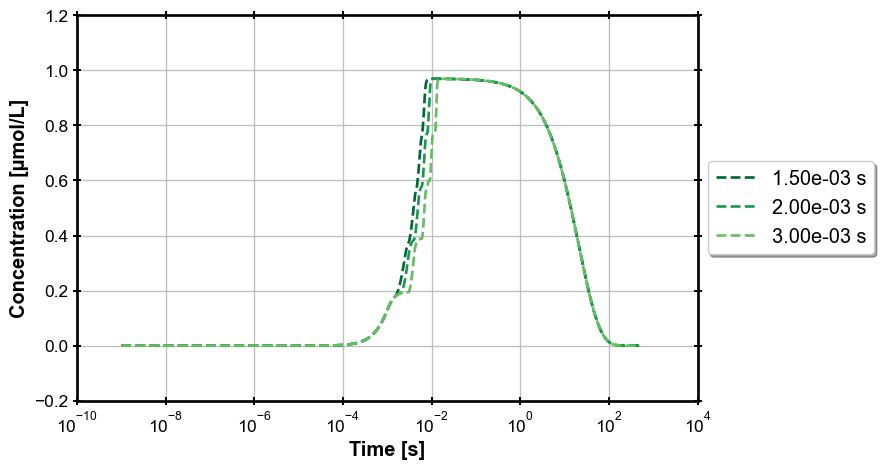

In [43]:
species = "ROO_r"
fig_man.set_brewer_map("RdYlGn", "diverging", 10, reverse=True)
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period:.2e} s", marker="")

    #ax.set_ylim(bottom=1e-6, top=2)
    #ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([0, 100])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    #ax.set_title("Biology related species")
    save_fig(fig, "CC__time__ROO_r")

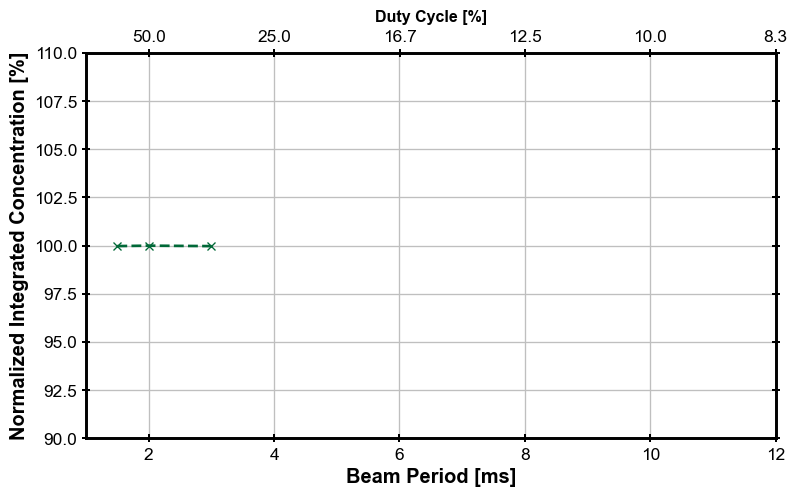

In [44]:
species = "ROO_r"
adf = pd.Series(dtype=np.float64)
for period, df in sims.items():
    mask = np.where((df.index>=1e-4)&(df.index<100))
    adf.loc[period] = simpson(y=df[species].values[mask].clip(min=0), x=df.index[mask])
    
with fig_man.open(f"Comparison of {species} ROO_r") as (fig, ax):
    
    ax.plot(adf.index*1e3, adf/adf.max()*100, marker="x")
    #ax.set_ylim(bottom=1e-6, top=2)
    ax.set_ylim([90, 110])
    ax.set_xlim([1, 12])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Beam Period [ms]")
    ax.set_ylabel("Normalized Integrated Concentration [%]")
    
    
    
    ax2 = ax.twiny()
    x_ticks = [round(1/elt*100,0) for elt in adf.index]
    ax2.set_xlim(np.round(1/np.array(ax.get_xlim())*100,0))
    ax2.grid(False)
    adapt_xticks(ax, ax2)
    fig.canvas.draw()
    labels = 1 / np.array(list(map(attrgetter("_x"), ax.get_xticklabels())))[1:] * 100

    ax2.set_xticklabels(np.around(labels, 1))
    ax2.set_title("Duty Cycle [%]", fontweight="bold", fontsize=12)
    save_fig(fig, "INT_CC__period__ROO_r")

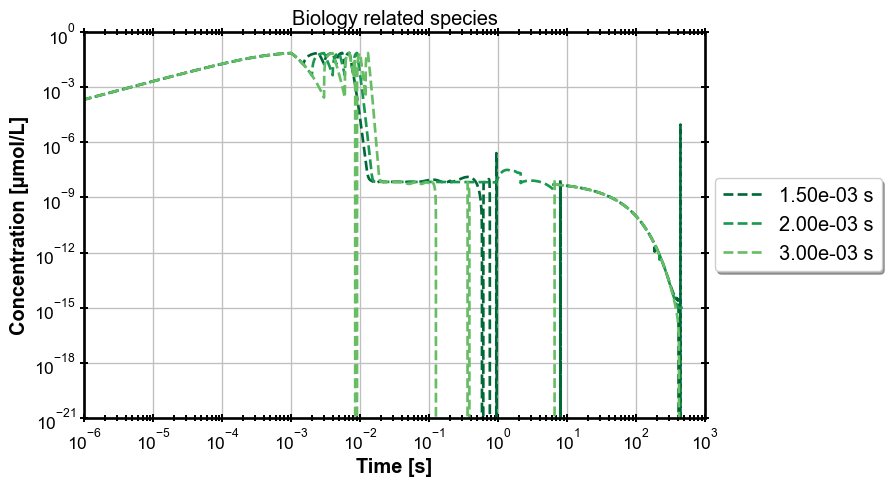

In [45]:
species = "R_r"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period:.2e} s", marker="")

    #ax.set_ylim(bottom=1e-6, top=1e2)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

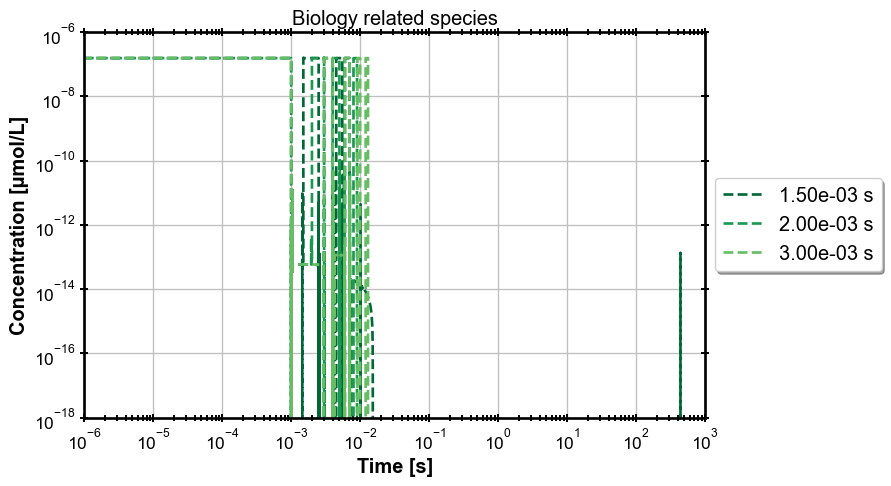

In [46]:
species = "OH_r"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period:.2e} s", marker="")

    #ax.set_ylim(bottom=1e-6, top=1e2)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

#### O2

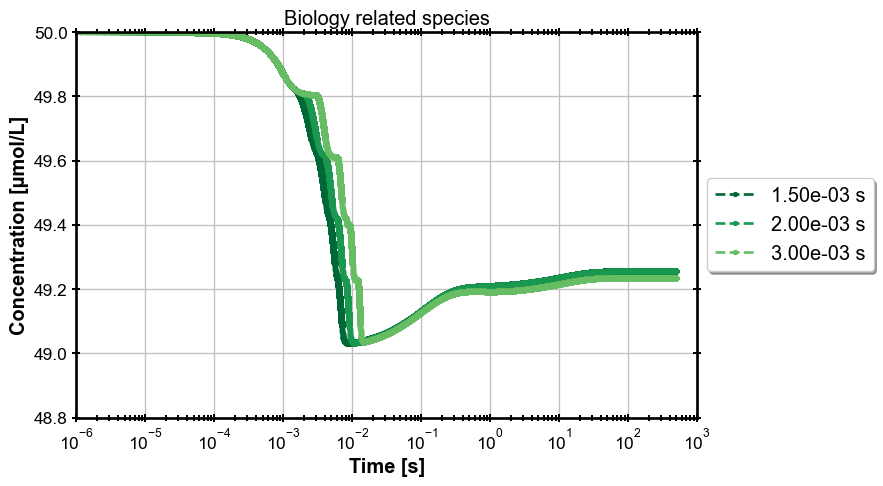

In [47]:
species = "O2"
with fig_man.open(f"Comparison of {species}") as (fig, ax):
    for period, df in sims.items():
        ax.plot(df.index, df[species], label=f"{period:.2e} s", marker=".")

    ax.set_ylim(top=50)
    ax.set_xlim([1e-6, RIGHT_LIMIT])
    #ax.set_xlim([10, 25])
    ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    RPlot.set_legend_right(ax)
    #ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Biology related species")

## Compare Chemical reaction rates

In [83]:
df_r.columns

Index(['KR_0', 'KR_1', 'KR_2', 'KR_3', 'KR_4', 'KR_5', 'KR_6', 'KR_7', 'KR_8',
       'KR_9', 'KR_10', 'KR_11', 'KR_12', 'KR_13', 'KR_14', 'KR_15', 'KR_16',
       'KR_17', 'KR_18', 'KR_19', 'KR_20', 'KR_21', 'KR_22', 'KR_23', 'KR_24',
       'KR_25', 'KR_26', 'KR_27', 'KR_28', 'KR_29', 'KR_30', 'KR_31', 'KR_32',
       'KR_33', 'KR_34', 'KR_35', 'KR_36', 'KR_37', 'G_e_aq', 'G_OH_r',
       'G_H_r', 'G_H2', 'G_H2O2', 'G_R_r', 'EZ_0'],
      dtype='object')

In [61]:
df_b

In [68]:
all_res

{0.0015: <radiopyo.sim_hand.ODEResult at 0x1bd0408c490>,
 0.002: <radiopyo.sim_hand.ODEResult at 0x1bd03c1bf90>,
 0.003: <radiopyo.sim_hand.ODEResult at 0x1bd21d9e590>,
 0.004: <radiopyo.sim_hand.ODEResult at 0x1bd2103ba50>,
 0.005: <radiopyo.sim_hand.ODEResult at 0x1bd25e6b190>,
 0.006: <radiopyo.sim_hand.ODEResult at 0x1bd25edc210>,
 0.007: <radiopyo.sim_hand.ODEResult at 0x1bd102f6590>,
 0.008: <radiopyo.sim_hand.ODEResult at 0x1bd21d9e1d0>,
 0.009: <radiopyo.sim_hand.ODEResult at 0x1bd25e673d0>,
 0.01: <radiopyo.sim_hand.ODEResult at 0x1bd03323f90>}

In [25]:
fig_man._fax

{'Water_radiolysis_related_species': FigName(fig=<Figure size 890x500.625 with 1 Axes>, ax=<Axes: >, idx=0, title='Water radiolysis related species', naked=False),
 'Comparison_of_ROO_r': FigName(fig=<Figure size 890x500.625 with 1 Axes>, ax=<Axes: xlabel='Time [s]', ylabel='Concentration [µmol/L]'>, idx=1, title='Comparison of ROO_r', naked=False),
 'Comparison_of_ROO_r_ROO_r': FigName(fig=<Figure size 890x500.625 with 2 Axes>, ax=<Axes: xlabel='Beam Period [ms]', ylabel='Normalized Integrated Concentration [%]'>, idx=2, title='Comparison of ROO_r ROO_r', naked=False),
 'Comparison_of_R_r': FigName(fig=<Figure size 890x500.625 with 1 Axes>, ax=<Axes: title={'center': 'Biology related species'}, xlabel='Time [s]', ylabel='Concentration [µmol/L]'>, idx=3, title='Comparison of R_r', naked=False),
 'Comparison_of_OH_r': FigName(fig=<Figure size 890x500.625 with 1 Axes>, ax=<Axes: title={'center': 'Biology related species'}, xlabel='Time [s]', ylabel='Concentration [µmol/L]'>, idx=4, title

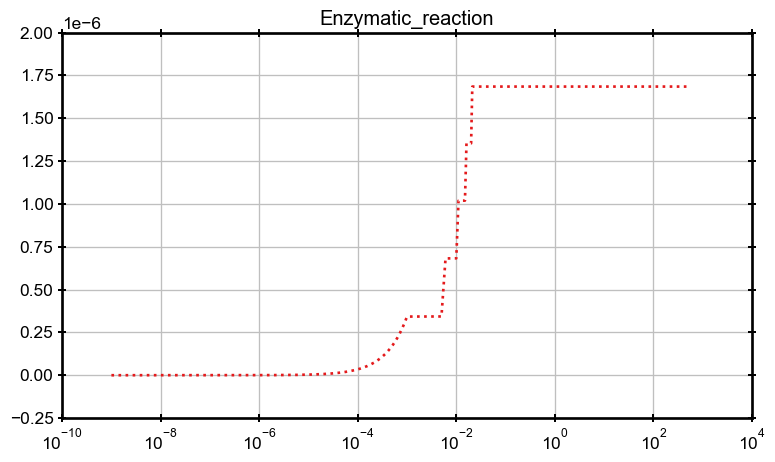

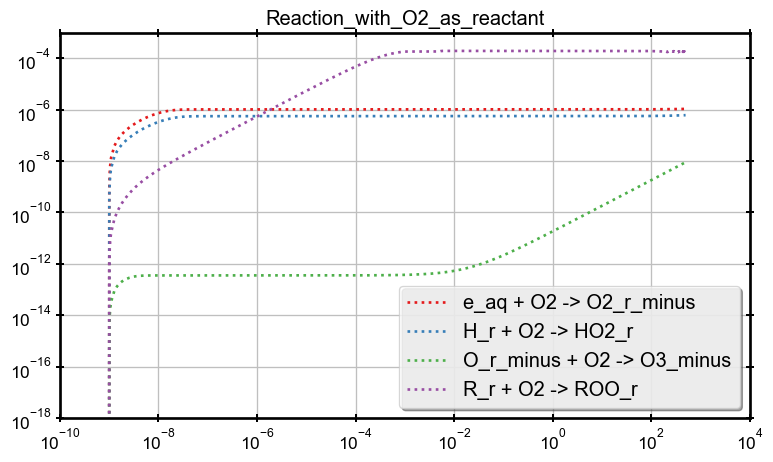

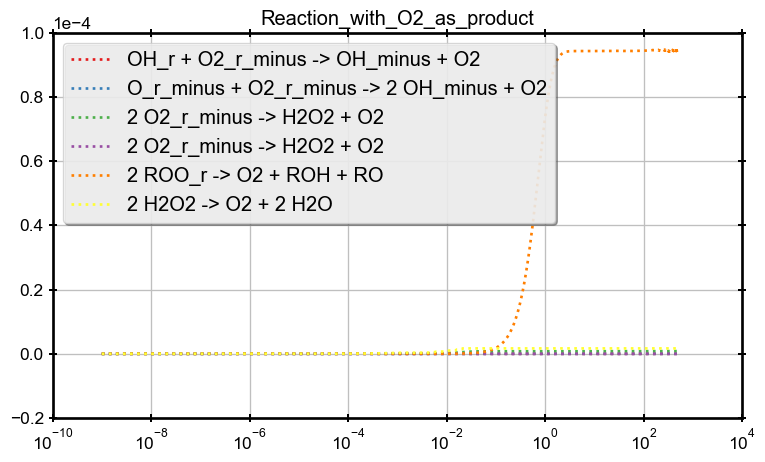

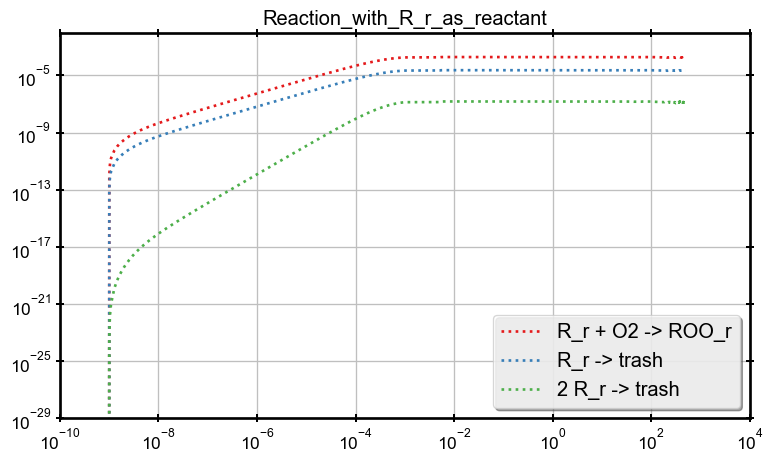

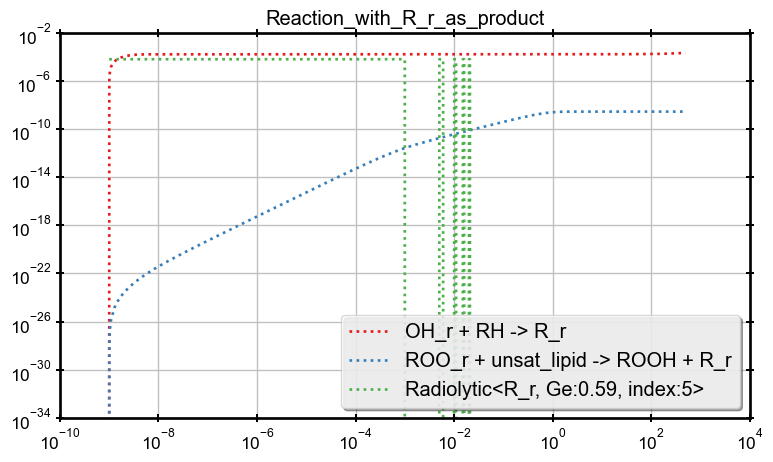

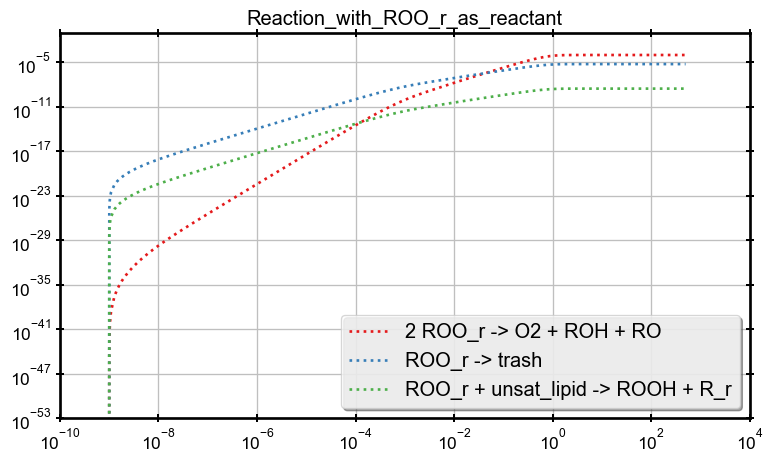

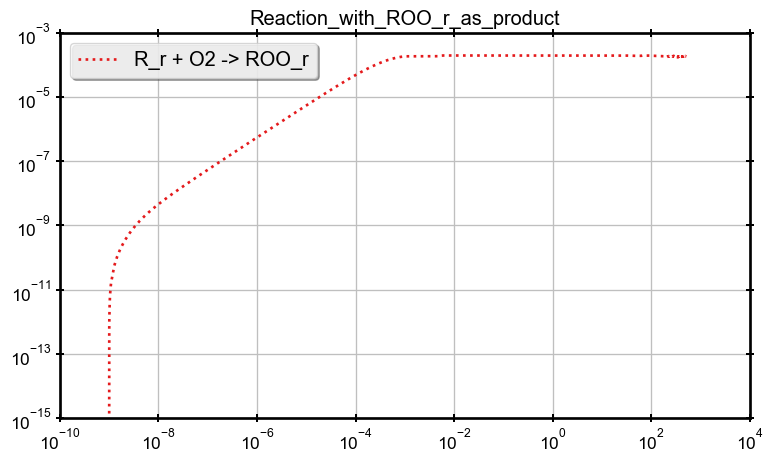

C:\Users\rtonneau\AppData\Local\Temp\ipykernel_18404\1964718746.py:60: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale("log")


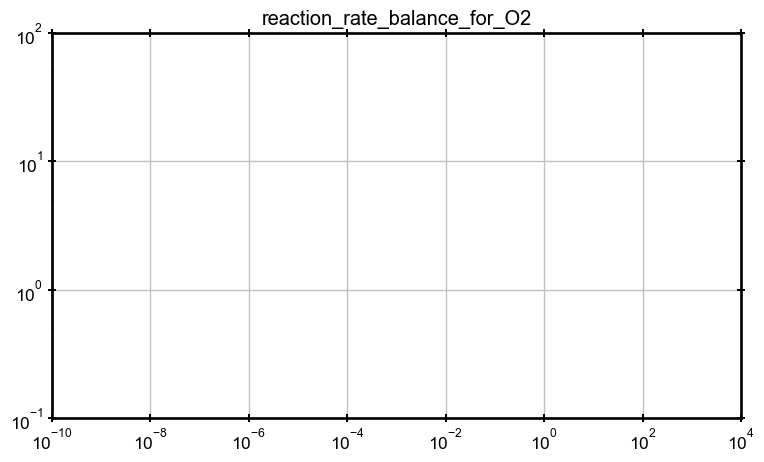

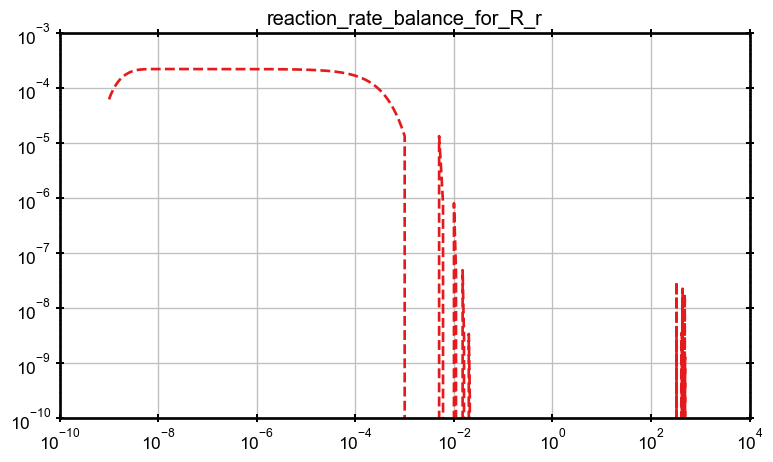

In [15]:
res = all_res[5e-3]
df_r = res.reconstruct_reactions()
df_b = res.species_balance_evolution()

fig_man.set_brewer_map("Set1", "qualitative", 6, reverse=False)

with fig_man.open(f"Enzymatic reaction") as (fig, ax):
    ax.semilogx(df_r.index, df_r["EZ_0"], label="fEZ_0", marker="", linestyle=":")
    ax.set_title(fig_man.last)

        
with fig_man.open(f"Reaction with O2 as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("O2"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
        ax.legend()
        ax.set_title(fig_man.last)
        ax.set_yscale("log")

with fig_man.open(f"Reaction with O2 as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("O2"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
        ax.legend()
        ax.set_title(fig_man.last)


with fig_man.open(f"Reaction with R_r as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")
    

with fig_man.open(f"Reaction with R_r as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

with fig_man.open(f"Reaction with ROO_r as reactant") as (fig, ax):
    for reaction in res.env.reactions_involving_reactant("ROO_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")
    

with fig_man.open(f"Reaction with ROO_r as product") as (fig, ax):
    for reaction in res.env.reactions_involving_product("ROO_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")
    ax.legend()
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

    
with fig_man.open(f"reaction rate balance for O2") as (fig, ax):
    ax.semilogx(df_b.index, df_b["O2"], marker="")
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

with fig_man.open(f"reaction rate balance for R_r") as (fig, ax):
    ax.semilogx(df_b.index, df_b["R_r"], marker="")
    ax.set_title(fig_man.last)
    ax.set_yscale("log")

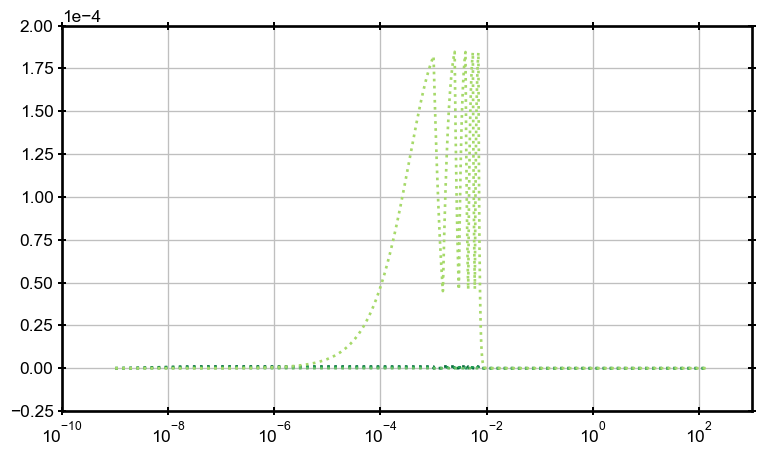

In [71]:
res = all_res[5e-3]
with fig_man.open(f"Reaction with R_r as product") as (fig, ax):
    df_r = all_res[1.5e-3].reconstruct_reactions()
    for reaction in res.env.reactions_involving_product("R_r"):
        ax.semilogx(df_r.index, df_r[reaction.as_label()], label=f"{reaction}", marker="", linestyle=":")

## Compare Pulses

**Integrate values per pulse**

In [51]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(int(PULSES_NUMBER)):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*uc.beam.timer.period, stop=(pulse+1)*uc.beam.timer.period)

NameError: name 'PULSES_NUMBER' is not defined

In [33]:
by_pulse

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,e_aq,H_r,H2,O2,O2_minus_minus,O3_minus,Fe_plus_plus_plus,RH_r,R_r,ROO_r,ROH,RO,ROOH
0,0.0,0.0,0.000038,0.0,0.0,0.000002,0.0,0.0,0.000063,9.999233,0.0,0.0,0.0,0.000285,0.000001,0.000615,0.0,0.0,0.0
1,0.0,0.0,0.000044,0.0,0.0,0.000004,0.0,0.0,0.000127,9.999921,0.0,0.000039,0.0,0.00053,0.0,0.000683,0.0,0.0,0.0
2,0.0,0.0,0.000044,0.0,0.0,0.000006,0.0,0.0,0.00019,9.999363,0.0,0.000137,0.0,0.000775,0.0,0.000747,0.0,0.0,0.0
3,0.0,0.0,0.000045,0.0,0.0,0.000007,0.0,0.0,0.000253,9.999367,0.0,0.000272,0.0,0.001022,0.0,0.000829,0.0,0.0,0.0
4,0.0,0.0,0.000044,0.0,0.0,0.000009,0.0,0.0,0.000315,9.953993,0.0,0.000429,0.0,0.001263,0.0,0.000911,0.0,0.0,0.0


### ON time

NameError: name 'by_pulse' is not defined

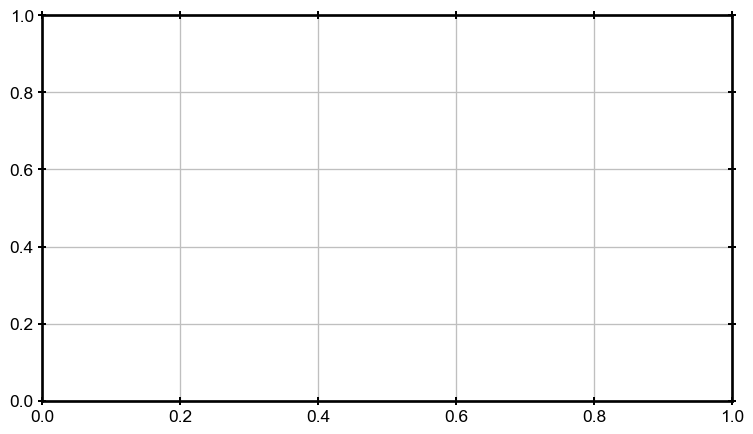

In [50]:
with fig_man.open(f"Pulse Integral") as (fig, ax):
    ax.plot(by_pulse.index+1, by_pulse["ROO_r"], label="ROO_r")
    ax.legend()

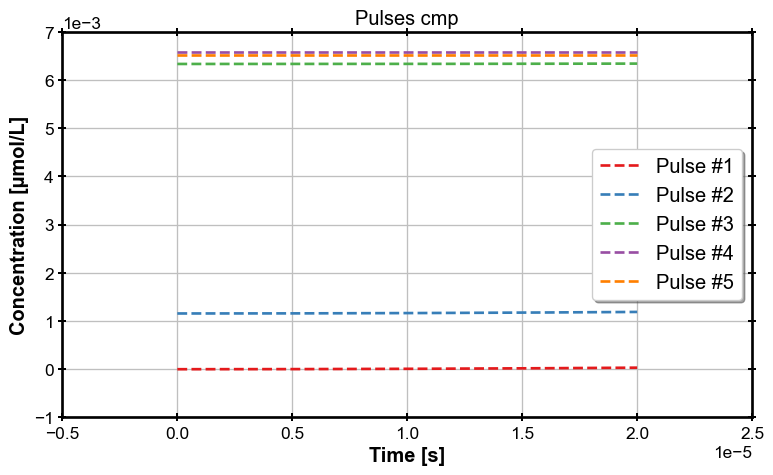

In [27]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period
        mask = (df.index>=start_pulse) & (df.index < start_pulse+uc.beam.timer.on_time)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,1])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")

### OFF Time

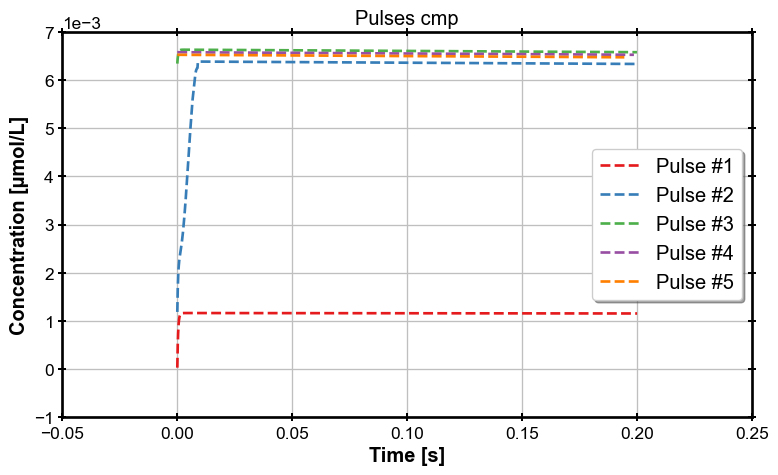

In [28]:
species = "ROO_r"
with fig_man.open(f"Pulses cmp") as (fig, ax):
    for pulse in range(int(PULSES_NUMBER)):
        start_pulse = pulse*uc.beam.timer.period + uc.beam.timer.on_time
        mask = (df.index>=start_pulse) & (df.index < (pulse+1)*uc.beam.timer.period)
        ax.plot(df.index[mask]-start_pulse, df.loc[mask, species], label=f"Pulse #{pulse+1}", marker="")

    #ax.set_ylim(bottom=1e-6, top=100)
    #ax.set_xlim([1e-6,0.12])
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Concentration [µmol/L]")
    ax.legend(fancybox=True, framealpha=1)
    ax.set_title("Pulses cmp")